It's working, but there are some errors that I'll fix it later

In [64]:
!git clone https://bitbucket.org/jadslim/german-traffic-signs/src/master/

fatal: destination path 'master' already exists and is not an empty directory.


In [65]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.datasets import mnist
from keras.models import Sequential, Model
from keras.layers import Dense
from keras.optimizers import Adam
from keras.utils import to_categorical
from keras.layers import Flatten, Conv2D, MaxPooling2D, Dropout
import pickle
import pandas as pd
import random

In [66]:
np.random.seed(0)

In [67]:
from re import X
with open('master/train.p', 'rb') as f:
  train_data = pickle.load(f)
with open('master/valid.p', 'rb') as f:
  val_data = pickle.load(f)
with open('master/test.p', 'rb') as f:
  test_data = pickle.load(f)

print(type(train_data))

X_train, y_train = train_data['features'], train_data['labels']
X_val, y_val = val_data['features'], val_data['labels']
X_test, y_test = test_data['features'], test_data['labels']

<class 'dict'>


In [68]:
print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(X_test.shape)

(34799, 32, 32, 3)
(34799,)
(4410, 32, 32, 3)
(12630, 32, 32, 3)


In [69]:
assert(X_train.shape[0] == y_train.shape[0]), "The number os imagens isnt equal to the number of labels"
assert(X_val.shape[0] == y_val.shape[0]), "The number os imagens isnt equal to the number of labels"
assert(X_test.shape[0] == y_test.shape[0]), "The number os imagens isnt equal to the number of labels"
assert(X_train.shape[1:] == (32,32,3)), "The dimensions of the images are wrong"
assert(X_val.shape[1:] == (32,32,3)), "The dimensions of the images are wrong"
assert(X_test.shape[1:] == (32,32,3)), "The dimensions of the images are wrong"


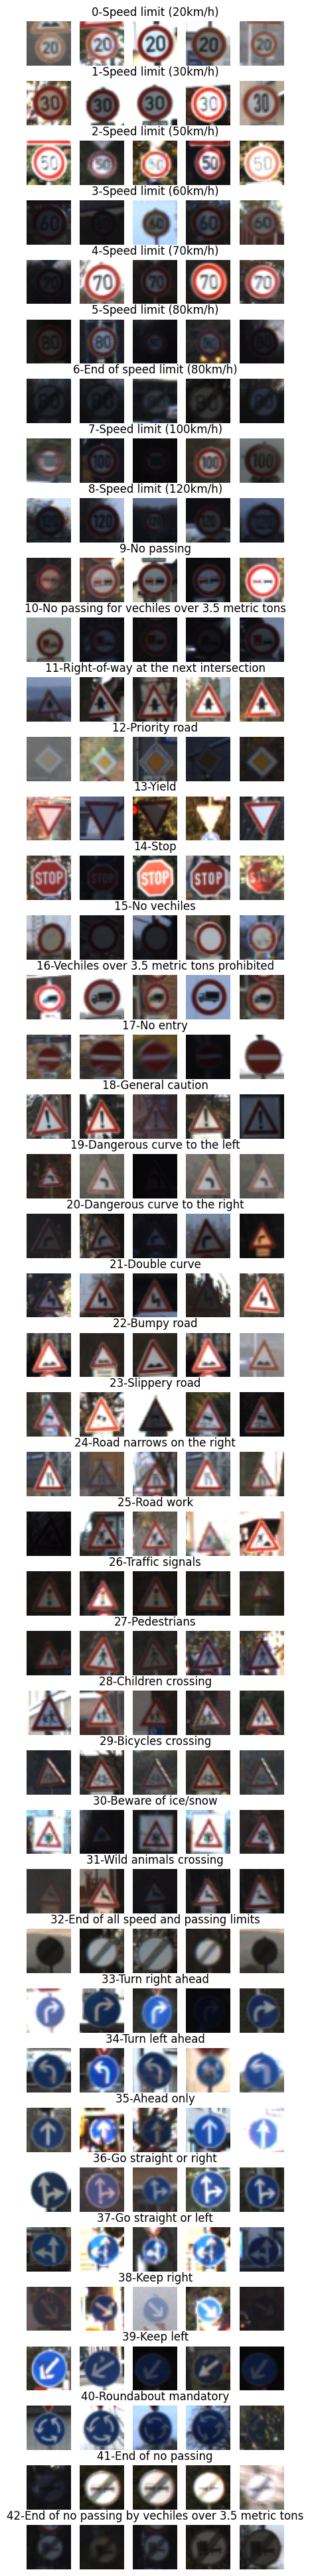

In [70]:
data = pd.read_csv('master/signnames.csv')

num_of_samples = []

cols = 5
num_class = 43

fig, axs = plt.subplots(nrows=num_class, ncols=cols, figsize=(5,50))
fig.tight_layout

for i in range(cols):
  for j, row in data.iterrows():
    x_selected = X_train[y_train == j]
    axs[j][i].imshow(x_selected[random.randint(0, len(x_selected)-1), :, :], cmap=plt.get_cmap('gray'))
    axs[j][i].axis('off')
    if i == 2:
      axs[j][i].set_title(str(j) + "-" + row["SignName"])
      num_of_samples.append(len(x_selected))

[180, 1980, 2010, 1260, 1770, 1650, 360, 1290, 1260, 1320, 1800, 1170, 1890, 1920, 690, 540, 360, 990, 1080, 180, 300, 270, 330, 450, 240, 1350, 540, 210, 480, 240, 390, 690, 210, 599, 360, 1080, 330, 180, 1860, 270, 300, 210, 210]


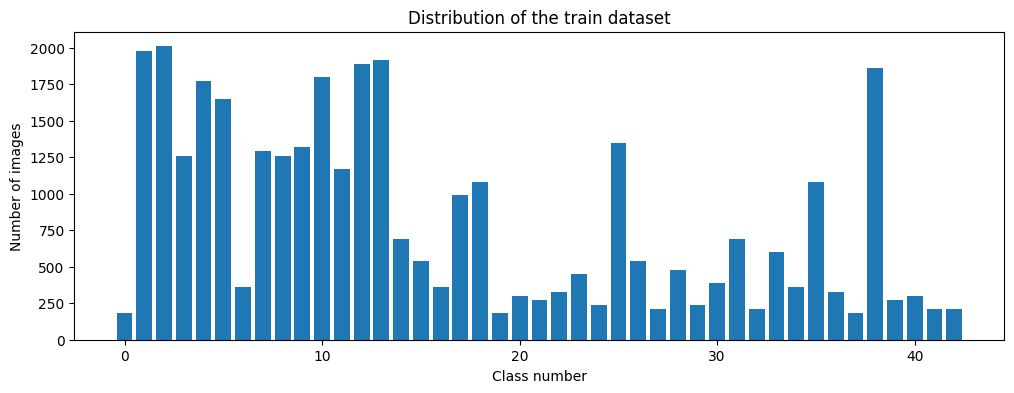

In [71]:
print(num_of_samples)
plt.figure(figsize=(12, 4))
plt.bar(range(0, num_class), num_of_samples)
plt.title("Distribution of the train dataset")
plt.xlabel("Class number")
plt.ylabel("Number of images")
plt.show()

(32, 32, 3)
1


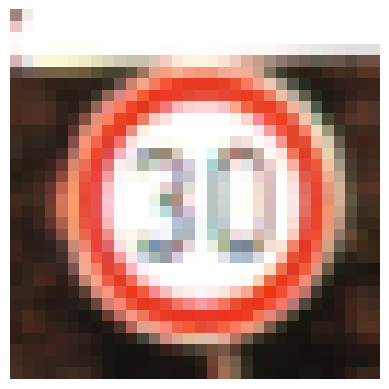

In [72]:
import cv2

plt.imshow(X_train[3000])
plt.axis('off')
print(X_train[3000].shape)
print(y_train[3000])

In [73]:
def grayscale(img):
  img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  return img
'''gray_img = grayscale(X_train[3000])
plt.imshow(gray_img)
plt.axis('off')
print(gray_img.shape)'''

"gray_img = grayscale(X_train[3000])\nplt.imshow(gray_img)\nplt.axis('off')\nprint(gray_img.shape)"

In [74]:
def equalize(img):
  img = cv2.equalizeHist(img)
  return img

'''equalize_img = equalize(gray_img)
plt.imshow(equalize_img)
plt.axis('off')
'''

"equalize_img = equalize(gray_img)\nplt.imshow(equalize_img)\nplt.axis('off')\n"

In [75]:

def preprossing(img):
  img = grayscale(img)
  img = equalize(img)
  img = img/255
  return img

X_train = np.array(list(map(preprossing, X_train)))
X_val = np.array(list(map(preprossing, X_val)))
X_test = np.array(list(map(preprossing, X_test)))

(34799, 32, 32)


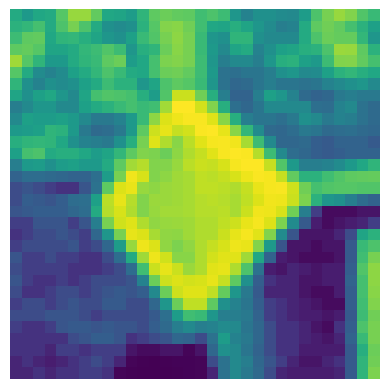

In [76]:
plt.imshow(X_train[random.randint(0, len(X_train) - 1)])
plt.axis('off')
print(X_train.shape)


In [77]:
X_train = X_train.reshape(34799, 32, 32, 1)
X_test = X_test.reshape(12630, 32, 32, 1)
X_val = X_val.reshape(4410, 32, 32, 1)

In [78]:
from keras.src.legacy.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(width_shift_range=0.1,
                             height_shift_range=0.1,
                             zoom_range=0.2,
                             shear_range=0.1,
                             rotation_range=10)

datagen.fit(X_train)

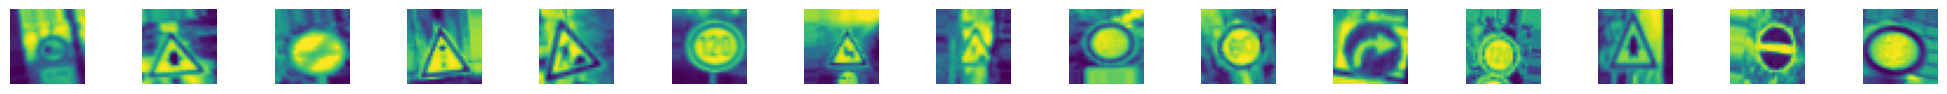

In [79]:
batches = datagen.flow(X_train, y_train, batch_size=15)
X_batch, y_batch = next(batches)
fig, axs = plt.subplots(1, 15, figsize=(20,5))
fig.tight_layout()

for i in range(15):
  axs[i].imshow(X_batch[i].reshape(32, 32))
  axs[i].axis('off')

In [80]:
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

(34799, 32, 32, 1)
(12630, 32, 32, 1)
(4410, 32, 32, 1)


In [81]:
y_train = to_categorical(y_train, 43)
y_test = to_categorical(y_test, 43)
y_val = to_categorical(y_val, 43)

In [82]:
# Define the leNet model function
def leNet_model():
  model = Sequential()
  model.add(Conv2D(60, (5, 5), input_shape=(32, 32, 1), activation='relu'))
  model.add(Conv2D(60, (5, 5), activation='relu'))
  model.add(MaxPooling2D(pool_size=(2, 2)))

  model.add(Conv2D(30, (3, 3), activation='relu'))
  model.add(Conv2D(30, (3, 3), activation='relu'))
  model.add(MaxPooling2D(pool_size=(2, 2)))
  #model.add(Dropout(0.5))

  model.add(Flatten())
  model.add(Dense(500, activation='relu'))
  model.add(Dropout(0.5))
  model.add(Dense(num_class, activation='softmax'))

  #compile model
  model.compile(Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
  return model

In [83]:
model = leNet_model()
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 60)     │         1,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 60)     │        90,060 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 60)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 30)     │        16,230 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 30)       │         8,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 30)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 500)            │       240,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 43)             │        21,543 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 378,023 (1.44 MB)

 Trainable params: 378,023 (1.44 MB)

 Non-trainable params: 0 (0.00 B)

None


In [84]:
history = model.fit(datagen.flow(X_train, y_train, batch_size=50), steps_per_epoch=2000, epochs=10, validation_data=(X_val, y_val), shuffle=1)

Epoch 1/10
 694/2000 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.2978 - loss: 2.5825

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.5123 - loss: 1.7243 - val_accuracy: 0.9188 - val_loss: 0.2562
Epoch 2/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8363 - loss: 0.5306 - val_accuracy: 0.9757 - val_loss: 0.0894
Epoch 3/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9002 - loss: 0.3226 - val_accuracy: 0.9744 - val_loss: 0.0779
Epoch 4/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9221 - loss: 0.2501 - val_accuracy: 0.9819 - val_loss: 0.0585
Epoch 5/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9389 - loss: 0.1930 - val_accuracy: 0.9841 - val_loss: 0.0525
Epoch 6/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9464 - loss: 0.1719 - val_accuracy: 0.9837 - val_loss: 0.0654
Epoch 7/10
 696/2000 ━━━━━━━━━━━━━━━━━━━━ 31s 24ms/step - accuracy: 0.9512 - loss: 0.1579

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.9526 - loss: 0.1519 - val_accuracy: 0.9884 - val_loss: 0.0454
Epoch 8/10
 695/2000 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.9580 - loss: 0.1386

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.9581 - loss: 0.1341 - val_accuracy: 0.9889 - val_loss: 0.0386
Epoch 9/10
 696/2000 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.9611 - loss: 0.1235

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9615 - loss: 0.1243 - val_accuracy: 0.9855 - val_loss: 0.0474
Epoch 10/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9649 - loss: 0.1123 - val_accuracy: 0.9889 - val_loss: 0.0376


Text(0.5, 0, 'epoch')

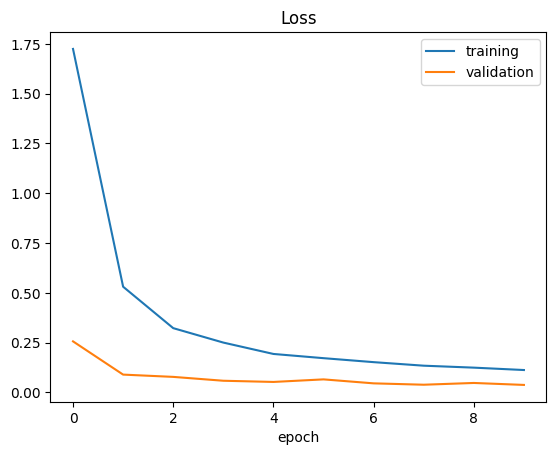

In [85]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['training', 'validation'])
plt.title('Loss')
plt.xlabel('epoch')

Text(0.5, 0, 'epoch')

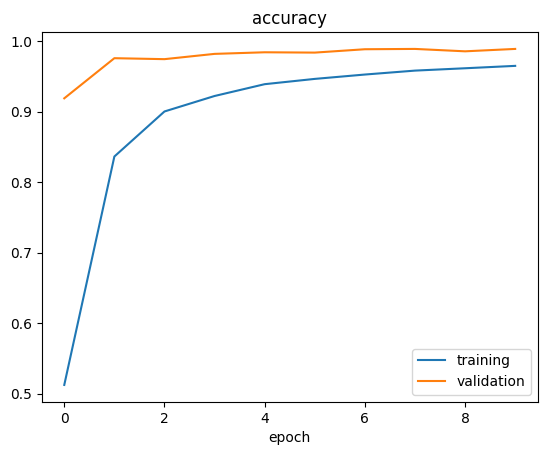

In [86]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['training', 'validation'])
plt.title('accuracy')
plt.xlabel('epoch')

In [87]:
score = model.evaluate(X_train, y_train, verbose=1)
print("Test score: ", score[0])
print("Test score: ", score[1])

1088/1088 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9950 - loss: 0.0173
Test score:  0.017289472743868828
Test score:  0.994999885559082


(np.float64(-0.5), np.float64(1299.5), np.float64(865.5), np.float64(-0.5))

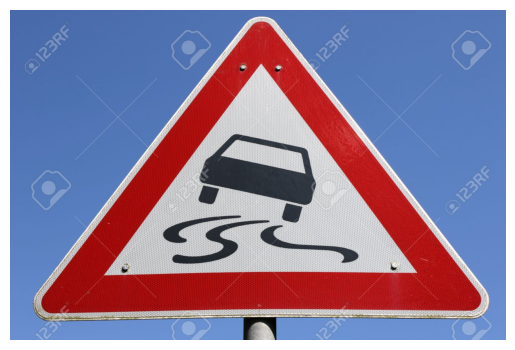

In [95]:
#fetch image
import requests
from PIL import Image

url = 'https://previews.123rf.com/images/bwylezich/bwylezich1608/bwylezich160800375/64914157-german-road-sign-slippery-road.jpg'
r = requests.get(url, stream=True)
img = Image.open(r.raw)
plt.imshow(img, cmap=plt.get_cmap('gray'))
plt.axis('off')


(32, 32)


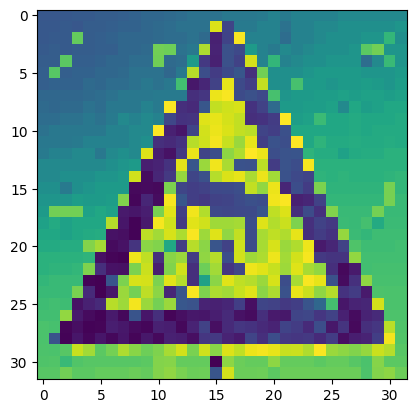

In [96]:
#Preprocess image

img = np.asarray(img)
img = cv2.resize(img, (32, 32))
img = preprossing(img)
plt.imshow(img)
print(img.shape)


In [97]:
# Reshape the image to add the batch dimension and the channel dimension
img = img.reshape(1, 32, 32, 1)

predictions = model.predict(img)
predicted_class = np.argmax(predictions, axis=-1)
print("predicted sign: " + str(predicted_class))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
predicted sign: [23]
